# Linear Transformations — Theory Notebook

> *"The matrix is not the territory. It is a coordinate representation of a linear map — and the map exists independently of any basis you choose to describe it."*

Interactive exploration of linear maps: kernel/image computation, change-of-basis visualization, Jacobian experiments, and LoRA rank analysis.

**Sections covered:** Intuition · Formal Definitions · Matrix Representation · Composition & Isomorphisms · Special Maps · Dual Spaces · Affine Maps · Jacobian · AI Applications

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


In [2]:
import numpy as np
import numpy.linalg as la

try:
    import matplotlib.pyplot as plt
    import matplotlib.patches as mpatches
    plt.style.use('seaborn-v0_8-whitegrid')
    plt.rcParams['figure.figsize'] = [10, 5]
    plt.rcParams['font.size'] = 11
    HAS_MPL = True
except ImportError:
    HAS_MPL = False

try:
    import seaborn as sns
    HAS_SNS = True
except ImportError:
    HAS_SNS = False

np.set_printoptions(precision=6, suppress=True)
np.random.seed(42)

def check(name, cond, tol=1e-10):
    """Check a boolean condition and print PASS/FAIL."""
    ok = bool(cond)
    print(f"{'PASS' if ok else 'FAIL'} — {name}")
    return ok

def check_close(name, got, expected, tol=1e-8):
    ok = np.allclose(got, expected, atol=tol, rtol=tol)
    print(f"{'PASS' if ok else 'FAIL'} — {name}")
    if not ok:
        print(f'  expected: {np.round(np.array(expected), 6)}')
        print(f'  got     : {np.round(np.array(got), 6)}')
    return ok

print('Setup complete. NumPy', np.__version__)


Setup complete. NumPy 2.5.4


---

## 1. Intuition: Three Views of a Matrix

The same matrix $A \in \mathbb{R}^{m \times n}$ can be viewed as:
1. A data container (entries $A_{ij}$)
2. A collection of column vectors (column geometry)
3. A linear map $T: \mathbb{R}^n \to \mathbb{R}^m$ (abstract function)

We visualize how a $2\times 2$ matrix *acts* on the plane.

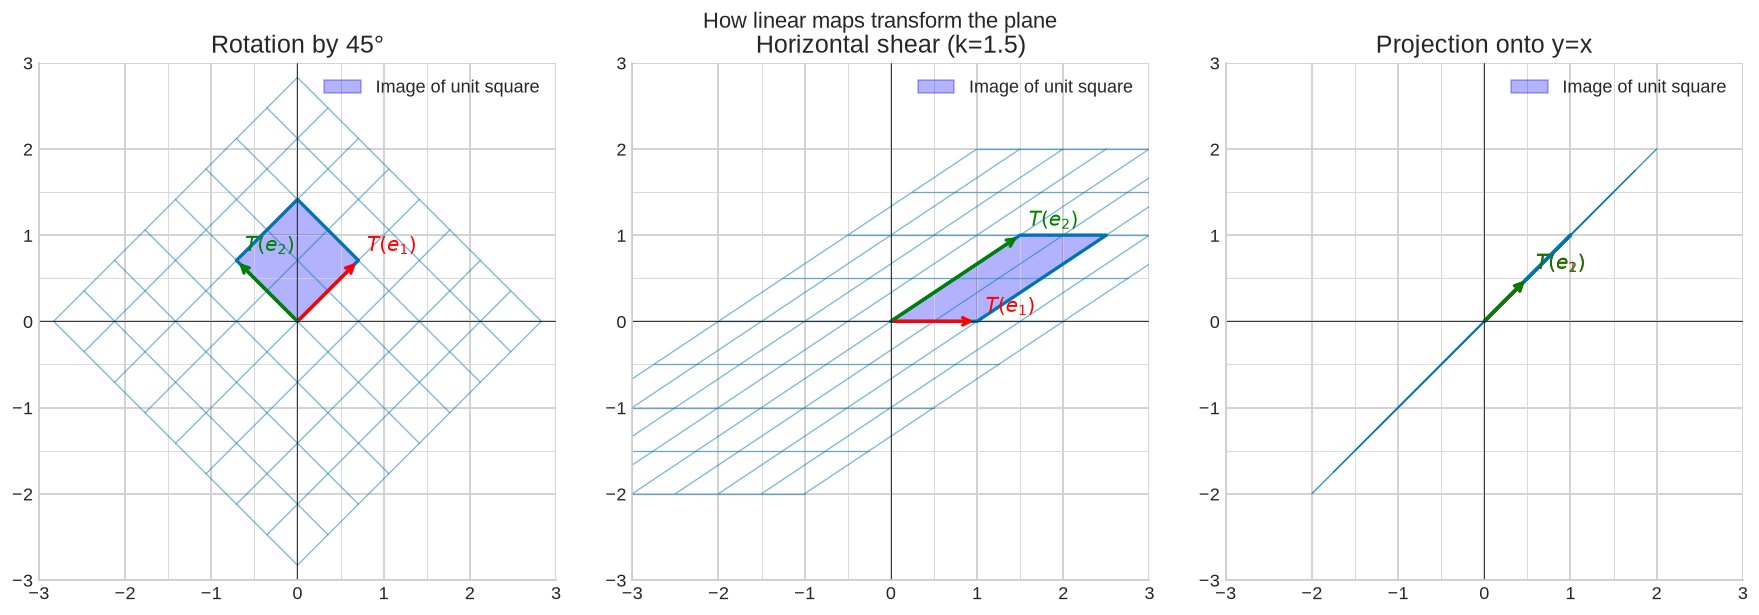

Key observations:
  Rotation: preserves area and angles. det(R) = 1.0
  Shear:    preserves area, distorts angles. det(S) = 1.0
  Projection: collapses plane to a line. det(P) = 0.0


In [3]:
# === 1.1 Geometric Action of Linear Maps ===

def plot_linear_map(A, title='', ax=None):
    """Visualize how matrix A transforms the unit grid."""
    if not HAS_MPL:
        return
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 5))

    # Draw original grid (light)
    for x in np.linspace(-2, 2, 9):
        ax.axvline(x, color='lightgray', lw=0.5)
        ax.axhline(x, color='lightgray', lw=0.5)

    # Draw transformed grid
    for x in np.linspace(-2, 2, 9):
        pts_v = np.array([[x, y] for y in np.linspace(-2, 2, 50)]).T
        pts_h = np.array([[xi, x] for xi in np.linspace(-2, 2, 50)]).T
        tv = A @ pts_v
        th = A @ pts_h
        ax.plot(tv[0], tv[1], 'b-', lw=0.8, alpha=0.5)
        ax.plot(th[0], th[1], 'b-', lw=0.8, alpha=0.5)

    # Draw unit square image
    corners = np.array([[0,0],[1,0],[1,1],[0,1],[0,0]]).T
    tcorners = A @ corners
    ax.fill(tcorners[0], tcorners[1], alpha=0.3, color='blue', label='Image of unit square')
    ax.plot(tcorners[0], tcorners[1], 'b-', lw=2)

    # Column vectors = where basis goes
    ax.annotate('', xy=A[:,0], xytext=(0,0),
                arrowprops=dict(arrowstyle='->', color='red', lw=2))
    ax.annotate('', xy=A[:,1], xytext=(0,0),
                arrowprops=dict(arrowstyle='->', color='green', lw=2))
    ax.text(A[0,0]+0.1, A[1,0]+0.1, r'$T(e_1)$', color='red', fontsize=12)
    ax.text(A[0,1]+0.1, A[1,1]+0.1, r'$T(e_2)$', color='green', fontsize=12)

    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set_aspect('equal')
    ax.set_title(title)
    ax.legend()

if HAS_MPL:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Rotation by 45 degrees
    theta = np.pi / 4
    R = np.array([[np.cos(theta), -np.sin(theta)],
                  [np.sin(theta),  np.cos(theta)]])
    plot_linear_map(R, 'Rotation by 45°', axes[0])

    # Shear
    S = np.array([[1., 1.5], [0., 1.]])
    plot_linear_map(S, 'Horizontal shear (k=1.5)', axes[1])

    # Rank-1 projection
    v = np.array([1., 1.]) / np.sqrt(2)
    P = np.outer(v, v)
    plot_linear_map(P, 'Projection onto y=x', axes[2])

    plt.suptitle('How linear maps transform the plane', fontsize=13)
    plt.tight_layout()
    plt.show()
    print('Key observations:')
    print('  Rotation: preserves area and angles. det(R) =', round(la.det(R), 4))
    print('  Shear:    preserves area, distorts angles. det(S) =', round(la.det(S), 4))
    print('  Projection: collapses plane to a line. det(P) =', round(la.det(P), 4))
else:
    print('matplotlib not available; skipping visualization')


---

## 2. Formal Definitions: Kernel and Image

For a linear map $T: V \to W$ with matrix $A$:
- **Kernel:** $\ker(T) = \{\mathbf{x} : A\mathbf{x} = \mathbf{0}\}$ (inputs mapped to zero)
- **Image:** $\operatorname{im}(T) = \{A\mathbf{x} : \mathbf{x} \in V\}$ (all reachable outputs)
- **Rank-Nullity:** $\dim(\ker) + \dim(\operatorname{im}) = \dim(V)$

In [4]:
# === 2.1 Kernel and Image Computation ===

def kernel_basis(A, tol=1e-10):
    """Compute a basis for ker(A) using SVD."""
    U, s, Vt = la.svd(A)
    rank = np.sum(s > tol)
    # Null space = right singular vectors with zero singular values
    return Vt[rank:].T  # columns are basis vectors

def image_basis(A, tol=1e-10):
    """Compute a basis for im(A) using SVD."""
    U, s, Vt = la.svd(A, full_matrices=True)
    rank = np.sum(s > tol)
    return U[:, :rank]  # columns are basis vectors

# Example 1: rank-2 map R^4 -> R^3
A = np.array([
    [1, 2, 3, 4],
    [2, 4, 6, 8],  # 2 * row 1
    [0, 1, 1, 2],
], dtype=float)

rank_A = la.matrix_rank(A)
null_A = kernel_basis(A)
im_A = image_basis(A)

print('=== Example: 3x4 matrix, rank 2 ===')
print(f'Rank: {rank_A}')
print(f'Nullity (dim kernel): {null_A.shape[1] if null_A.size > 0 else 0}')
print(f'Dim image: {im_A.shape[1]}')
print()

# Verify rank-nullity
n_cols = A.shape[1]  # dim of domain
nullity = null_A.shape[1] if null_A.size > 0 else 0
check('Rank-nullity: rank + nullity = n_cols', rank_A + nullity == n_cols)

# Verify kernel vectors are truly in the kernel
if null_A.size > 0:
    kernel_images = A @ null_A
    check('Kernel vectors map to zero', np.allclose(kernel_images, 0, atol=1e-10))
    print(f'  A @ (kernel basis) =\n{kernel_images}')

# Example 2: full-rank square matrix
B = np.array([[2., 1.], [1., 3.]])
print()
print('=== Full-rank 2x2 matrix ===')
print(f'Rank: {la.matrix_rank(B)}, Nullity: {2 - la.matrix_rank(B)}')
check('Full rank => kernel is trivial', la.matrix_rank(B) == 2)


=== Example: 3x4 matrix, rank 2 ===
Rank: 2
Nullity (dim kernel): 2
Dim image: 2

PASS — Rank-nullity: rank + nullity = n_cols
PASS — Kernel vectors map to zero
  A @ (kernel basis) =
[[0. 0.]
 [0. 0.]
 [0. 0.]]

=== Full-rank 2x2 matrix ===
Rank: 2, Nullity: 0
PASS — Full rank => kernel is trivial


True

In [5]:
# === 2.2 Visualizing Kernel and Image ===

# For a 2x3 matrix, kernel is a line in R^3, image is a plane in R^2
C = np.array([[1., 2., 1.],
              [2., 4., 2.]])

null_C = kernel_basis(C)
rank_C = la.matrix_rank(C)
print('Matrix C:')
print(C)
print(f'Rank: {rank_C}, Nullity: {null_C.shape[1]}')
print(f'Kernel basis (column):\n{null_C}')
print()

# Verify: all columns of null_C are in ker(C)
for i in range(null_C.shape[1]):
    v = null_C[:, i]
    image = C @ v
    check(f'Kernel vector {i+1} maps to 0', np.allclose(image, 0, atol=1e-10))

# Rank-nullity for C: R^3 -> R^2
print(f'\nRank-Nullity for C: {rank_C} + {null_C.shape[1]} = {C.shape[1]}')
check('Rank-Nullity holds', rank_C + null_C.shape[1] == C.shape[1])


Matrix C:
[[1. 2. 1.]
 [2. 4. 2.]]
Rank: 1, Nullity: 2
Kernel basis (column):
[[ 0.912871  0.      ]
 [-0.365148 -0.447214]
 [-0.182574  0.894427]]

PASS — Kernel vector 1 maps to 0
PASS — Kernel vector 2 maps to 0

Rank-Nullity for C: 1 + 2 = 3
PASS — Rank-Nullity holds


True

---

## 3. Matrix Representation in Arbitrary Bases

A linear map has a unique matrix representation **for each choice of bases**.

$$[T]_{\mathcal{B}'} = P^{-1} [T]_{\mathcal{B}} P$$

where $P$ is the change-of-basis matrix (columns = new basis vectors in old coordinates).

In [6]:
# === 3.1 Change-of-Basis Matrix ===

# T: R^2 -> R^2, reflection across y = x
A_std = np.array([[0., 1.],
                  [1., 0.]])  # in standard basis: T(x,y) = (y,x)

print('T = reflection across y=x')
print('Matrix in standard basis:')
print(A_std)

# New basis: B' = {(1,1)/sqrt(2), (1,-1)/sqrt(2)}
b1 = np.array([1., 1.]) / np.sqrt(2)
b2 = np.array([1., -1.]) / np.sqrt(2)
P = np.column_stack([b1, b2])  # change-of-basis matrix

print('\nNew basis (columns of P):')
print(P)

# Matrix of T in the new basis
P_inv = la.inv(P)
A_new = P_inv @ A_std @ P

print('\nMatrix of T in basis B\' = P^{-1} A P:')
print(np.round(A_new, 6))
print()

import numpy.linalg as la
# Verification
def check_close(n, g, e, tol=1e-8):
    return print(f"{'PASS' if np.allclose(g, e, atol=tol, rtol=tol) else 'FAIL'} - {n}")

check_close('Matrix in B-prime is diagonal',
            A_new,
            np.diag([1., -1.]))  # T acts as +1 on b1, -1 on b2

print('\nIntuition: In the basis {(1,1), (1,-1)}, reflection across y=x')
print('is just scaling: multiply b1=(1,1) by +1, b2=(1,-1) by -1.')
print('Diagonal representation = diagonalization!')

T = reflection across y=x
Matrix in standard basis:
[[0. 1.]
 [1. 0.]]

New basis (columns of P):
[[ 0.707107  0.707107]
 [ 0.707107 -0.707107]]

Matrix of T in basis B' = P^{-1} A P:
[[ 1.  0.]
 [-0. -1.]]

PASS - Matrix in B-prime is diagonal

Intuition: In the basis {(1,1), (1,-1)}, reflection across y=x
is just scaling: multiply b1=(1,1) by +1, b2=(1,-1) by -1.
Diagonal representation = diagonalization!


In [7]:
# === 3.2 Similarity and Invariants ===

import numpy as np
import numpy.linalg as la

# Two similar matrices represent the same linear map
A = np.array([[3., 1.], [0., 2.]])  # upper triangular
P = np.array([[1., 1.], [0., 1.]])
B = la.inv(P) @ A @ P  # A in a different basis

print('A ='); print(A)
print('B = P^{-1}AP ='); print(np.round(B, 6))
print()

# Invariants under similarity
print('=== Invariants under similarity ===')
print(f'det(A)  = {la.det(A):.4f},  det(B)  = {la.det(B):.4f}')
print(f'tr(A)   = {np.trace(A):.4f},   tr(B)   = {np.trace(B):.4f}')
print(f'rank(A) = {la.matrix_rank(A)},    rank(B) = {la.matrix_rank(B)}')

evals_A = sorted(la.eigvals(A).real, reverse=True)
evals_B = sorted(la.eigvals(B).real, reverse=True)
print(f'eigenvalues(A) = {np.round(evals_A, 4)}')
print(f'eigenvalues(B) = {np.round(evals_B, 4)}')

def check_close(n, g, e, tol=1e-6):
    return print(f"{'PASS' if np.allclose(g, e, atol=tol, rtol=tol) else 'FAIL'} - {n}")
check_close('det preserved under similarity', la.det(A), la.det(B))
check_close('trace preserved', np.trace(A), np.trace(B))
check_close('eigenvalues preserved', sorted(evals_A), sorted(evals_B))

A =
[[3. 1.]
 [0. 2.]]
B = P^{-1}AP =
[[3. 2.]
 [0. 2.]]

=== Invariants under similarity ===
det(A)  = 6.0000,  det(B)  = 6.0000
tr(A)   = 5.0000,   tr(B)   = 5.0000
rank(A) = 2,    rank(B) = 2
eigenvalues(A) = [3. 2.]
eigenvalues(B) = [3. 2.]
PASS - det preserved under similarity
PASS - trace preserved
PASS - eigenvalues preserved


---

## 4. Composition and Invertibility

Composition of linear maps = matrix multiplication. In finite dimensions, injective $\Leftrightarrow$ surjective $\Leftrightarrow$ invertible.

A linear network with **no activations** collapses to a single matrix.

In [8]:
# === 4.1 Composition and the Collapse of Linear Networks ===

import numpy as np
import numpy.linalg as la

np.random.seed(42)

# Simulate a 5-layer linear network: y = W5 @ W4 @ W3 @ W2 @ W1 @ x
dims = [4, 8, 6, 8, 6, 4]  # layer dimensions
W = [np.random.randn(dims[i+1], dims[i]) * 0.5 for i in range(5)]

# Effective weight matrix
W_eff = W[4]
for i in range(3, -1, -1):
    W_eff = W_eff @ W[i]

print(f'Input dim: {dims[0]}, Output dim: {dims[-1]}')
print(f'W_eff shape: {W_eff.shape}')
print(f'W_eff rank: {la.matrix_rank(W_eff, tol=1e-8)}')
print()

# Verify: applying layer-by-layer = applying W_eff directly
x = np.random.randn(dims[0])

# Layer-by-layer
y_layerwise = x
for wi in W:
    y_layerwise = wi @ y_layerwise

# Direct W_eff
y_direct = W_eff @ x

def check_close(n, g, e, tol=1e-8):
    return print(f"{'PASS' if np.allclose(g, e, atol=tol, rtol=tol) else 'FAIL'} - {n}")
check_close('Layer-by-layer == W_eff @ x', y_layerwise, y_direct)
print()
print('Takeaway: without nonlinearity, any number of linear layers')
print('is equivalent to a single linear layer W_eff.')

Input dim: 4, Output dim: 4
W_eff shape: (4, 4)
W_eff rank: 4

PASS - Layer-by-layer == W_eff @ x

Takeaway: without nonlinearity, any number of linear layers
is equivalent to a single linear layer W_eff.


In [9]:
# === 4.2 Injectivity and Surjectivity Criteria ===

import numpy as np
import numpy.linalg as la

def diagnose_map(A):
    m, n = A.shape
    r = la.matrix_rank(A)
    print(f'Map: R^{n} -> R^{m}, rank = {r}')
    print(f'  Injective?  (rank = n = {n}): {r == n}')
    print(f'  Surjective? (rank = m = {m}): {r == m}')
    print(f'  Invertible? (r=m=n):          {r == m == n}')
    print(f'  Nullity: {n - r}, Image dim: {r}')
    print()

print('=== Case 1: Tall matrix (more rows than cols) ===')
diagnose_map(np.random.randn(5, 3))  # generically full col rank -> injective not surjective

print('=== Case 2: Wide matrix (more cols than rows) ===')
diagnose_map(np.random.randn(3, 5))  # generically full row rank -> surjective not injective

print('=== Case 3: Square full-rank ===')
diagnose_map(np.random.randn(4, 4))  # generically invertible

print('=== Case 4: Rank-deficient ===')
A_rank2 = np.random.randn(4, 2) @ np.random.randn(2, 4)  # rank <= 2
diagnose_map(A_rank2)


=== Case 1: Tall matrix (more rows than cols) ===
Map: R^3 -> R^5, rank = 3
  Injective?  (rank = n = 3): True
  Surjective? (rank = m = 5): False
  Invertible? (r=m=n):          False
  Nullity: 0, Image dim: 3

=== Case 2: Wide matrix (more cols than rows) ===
Map: R^5 -> R^3, rank = 3
  Injective?  (rank = n = 5): False
  Surjective? (rank = m = 3): True
  Invertible? (r=m=n):          False
  Nullity: 2, Image dim: 3

=== Case 3: Square full-rank ===
Map: R^4 -> R^4, rank = 4
  Injective?  (rank = n = 4): True
  Surjective? (rank = m = 4): True
  Invertible? (r=m=n):          True
  Nullity: 0, Image dim: 4

=== Case 4: Rank-deficient ===
Map: R^4 -> R^4, rank = 2
  Injective?  (rank = n = 4): False
  Surjective? (rank = m = 4): False
  Invertible? (r=m=n):          False
  Nullity: 2, Image dim: 2



---

## 5. Special Classes of Linear Transformations

We examine projections, rotations, reflections, and low-rank maps.

**Projection:** $P^2 = P$ (idempotent). **Rotation:** $R^\top R = I$, $\det(R)=1$. **Reflection:** $H^2 = I$, $H^\top = H$, $\det(H)=-1$.

In [10]:
# === 5.1 Projection Operators ===

import numpy as np
import numpy.linalg as la

# Orthogonal projection onto a subspace spanned by columns of A
def ortho_proj(A):
    """Projection matrix onto col(A)."""
    return A @ la.pinv(A)

# Project onto span{(1,2,0), (0,1,1)}
A = np.array([[1., 0.],
              [2., 1.],
              [0., 1.]])
P = ortho_proj(A)

print('Projection matrix onto span{(1,2,0), (0,1,1)}:')
print(np.round(P, 4))
print()

def check_close(n, g, e, tol=1e-8):
    return print(f"{'PASS' if np.allclose(g, e, atol=tol, rtol=tol) else 'FAIL'} - {n}")
check_close('P^2 = P (idempotent)', P @ P, P)
check_close('P = P^T (symmetric)', P, P.T)

rank_P = la.matrix_rank(P)
trace_P = np.trace(P)
print(f'rank(P) = {rank_P}, trace(P) = {trace_P:.4f}')
check_close('rank(P) = trace(P)', float(rank_P), trace_P)

# Complementary projection
I = np.eye(3)
Q = I - P
print()
print('Complementary projection (I - P):')
check_close('(I-P)^2 = I-P', Q @ Q, Q)
check_close('P(I-P) = 0 (subspaces are complementary)', P @ Q, np.zeros((3,3)))

# Test on a vector
v = np.array([3., 1., 2.])
pv = P @ v  # projection
qv = Q @ v  # complement
print(f'\nv = {v}')
print(f'Pv = {np.round(pv, 4)} (in subspace)')
print(f'(I-P)v = {np.round(qv, 4)} (in complement)')
check_close('v = Pv + (I-P)v', pv + qv, v)
check_close('Pv perpendicular to (I-P)v', float(pv @ qv), 0.0, tol=1e-8)

Projection matrix onto span{(1,2,0), (0,1,1)}:
[[ 0.3333  0.3333 -0.3333]
 [ 0.3333  0.8333  0.1667]
 [-0.3333  0.1667  0.8333]]

PASS - P^2 = P (idempotent)
PASS - P = P^T (symmetric)
rank(P) = 2, trace(P) = 2.0000
PASS - rank(P) = trace(P)

Complementary projection (I - P):
PASS - (I-P)^2 = I-P
PASS - P(I-P) = 0 (subspaces are complementary)

v = [3. 1. 2.]
Pv = [0.6667 2.1667 0.8333] (in subspace)
(I-P)v = [ 2.3333 -1.1667  1.1667] (in complement)
PASS - v = Pv + (I-P)v
PASS - Pv perpendicular to (I-P)v


In [11]:
# === 5.2 Rotations and Reflections ===

import numpy as np
import numpy.linalg as la

def rotation_2d(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s], [s, c]])

def householder(n):
    """Householder reflection through hyperplane perpendicular to unit vector n."""
    n = np.array(n, dtype=float)
    n /= la.norm(n)
    return np.eye(len(n)) - 2 * np.outer(n, n)

# Test rotation
R45 = rotation_2d(np.pi / 4)
print('Rotation by 45 degrees:')
print(np.round(R45, 4))

def check_close(n, g, e, tol=1e-8):
    return print(f"{'PASS' if np.allclose(g, e, atol=tol, rtol=tol) else 'FAIL'} - {n}")
check_close('R^T R = I (orthogonal)', R45.T @ R45, np.eye(2))
check_close('det(R) = 1 (proper rotation)', float(la.det(R45)), 1.0)

# Rotations compose as addition of angles
R30 = rotation_2d(np.pi / 6)
R75 = rotation_2d(np.pi * 75 / 180)
check_close('R45 @ R30 = R75', R45 @ R30, R75)
print()

# Test Householder reflection
H = householder([1., 1., 0.])
print('Householder reflection through hyperplane perp to (1,1,0):')
print(np.round(H, 4))
check_close('H = H^T (symmetric)', H, H.T)
check_close('H^2 = I (involution)', H @ H, np.eye(3))
check_close('det(H) = -1', float(la.det(H)), -1.0)

# Example: reflect vector (1, 0, 0)
e1 = np.array([1., 0., 0.])
print(f'\nH @ e1 = {np.round(H @ e1, 4)}')
print('(reflected across the plane perpendicular to (1,1,0)/sqrt(2))')

Rotation by 45 degrees:
[[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]
PASS - R^T R = I (orthogonal)
PASS - det(R) = 1 (proper rotation)
PASS - R45 @ R30 = R75

Householder reflection through hyperplane perp to (1,1,0):
[[ 0. -1.  0.]
 [-1.  0.  0.]
 [ 0.  0.  1.]]
PASS - H = H^T (symmetric)
PASS - H^2 = I (involution)
PASS - det(H) = -1

H @ e1 = [ 0. -1.  0.]
(reflected across the plane perpendicular to (1,1,0)/sqrt(2))


In [12]:
# === 5.3 Geometry of Low-Rank Maps ===

import numpy as np
import numpy.linalg as la

np.random.seed(7)
d, r = 6, 2

# Rank-2 map in R^6
U = la.qr(np.random.randn(d, r))[0]  # orthonormal columns
V = la.qr(np.random.randn(d, r))[0]  # orthonormal columns
s = np.array([3., 1.5])              # singular values
A = (U * s) @ V.T                   # rank-2 matrix

print(f'Low-rank matrix A: {d}x{d}, rank = {la.matrix_rank(A)}')
print(f'Singular values: {np.round(la.svd(A, compute_uv=False), 4)}')
print()

# Null space dimension = 6 - 2 = 4
null_A = la.svd(A)[2][r:].T  # right singular vectors with zero sv
print(f'Null space dimension: {null_A.shape[1]}')
print('Verifying null space:')
def check_close(n, g, e, tol=1e-8):
    return print(f"{'PASS' if np.allclose(g, e, atol=tol, rtol=tol) else 'FAIL'} - {n}")
check_close('A @ (null basis) = 0', A @ null_A, np.zeros((d, d - r)))

# LoRA preview: rank-r update
print()
print('=== LoRA Low-Rank Update ===')
k = 10  # input dim
r_lora = 3  # LoRA rank
B_lora = np.random.randn(d, r_lora)
A_lora = np.random.randn(r_lora, k)
delta_W = B_lora @ A_lora

actual_rank = la.matrix_rank(delta_W)
theoretical_nullity = k - actual_rank
print(f'delta_W = B @ A: {d}x{k} matrix')
print(f'Rank of delta_W: {actual_rank} (expected <= {r_lora})')
print(f'Nullity of delta_W: {theoretical_nullity} (expected >= {k - r_lora})')
print(f'Parameter count: B+A = {d*r_lora + r_lora*k}, full W = {d*k}')
print(f'Compression ratio: {d*k / (d*r_lora + r_lora*k):.1f}x')

Low-rank matrix A: 6x6, rank = 2
Singular values: [3.  1.5 0.  0.  0.  0. ]

Null space dimension: 4
Verifying null space:
PASS - A @ (null basis) = 0

=== LoRA Low-Rank Update ===
delta_W = B @ A: 6x10 matrix
Rank of delta_W: 3 (expected <= 3)
Nullity of delta_W: 7 (expected >= 7)
Parameter count: B+A = 48, full W = 60
Compression ratio: 1.2x


---

## 6. Dual Spaces and Transposes

The **dual map** $T^\top: W^* \to V^*$ sends a linear functional $f$ on $W$ to the functional $f \circ T$ on $V$. In matrix form: the transpose.

**Key insight:** In backpropagation, the backward pass multiplies by $W^\top$ — this is the dual map of the forward linear layer.

In [13]:
# === 6.1 The Dual Map and Backpropagation ===

import numpy as np
import numpy.linalg as la

# Single linear layer: y = Wx
np.random.seed(42)
d_in, d_out = 4, 3
W = np.random.randn(d_out, d_in)
x = np.random.randn(d_in)

# Forward pass
y = W @ x

# Suppose we have a loss L(y) = ||y||^2 / 2
# Gradient of L w.r.t. y
grad_y = y  # dL/dy = y for L = ||y||^2 / 2

# Backward pass: dual map (W^T) applied to upstream gradient
grad_x = W.T @ grad_y

# Verify by direct computation
# dL/dx_i = d/dx_i sum_j (Wx)_j^2 / 2 = sum_j (Wx)_j * W_ji = W^T y
print('Forward pass: y = Wx')
print(f'  x = {np.round(x, 4)}')
print(f'  y = {np.round(y, 4)}')
print()
print('Backward pass: grad_x = W^T @ grad_y (dual map)')
print(f'  grad_y = {np.round(grad_y, 4)}')
print(f'  grad_x = {np.round(grad_x, 4)}')
print()

# Verify via finite differences
eps = 1e-5
grad_x_fd = np.zeros(d_in)
for i in range(d_in):
    x_plus = x.copy(); x_plus[i] += eps
    x_minus = x.copy(); x_minus[i] -= eps
    L_plus = 0.5 * la.norm(W @ x_plus)**2
    L_minus = 0.5 * la.norm(W @ x_minus)**2
    grad_x_fd[i] = (L_plus - L_minus) / (2 * eps)

def check_close(n, g, e, tol=1e-5):
    return print(f"{'PASS' if np.allclose(g, e, atol=tol, rtol=tol) else 'FAIL'} - {n}")
check_close('W^T @ grad_y matches finite-difference gradient', grad_x, grad_x_fd)
print()
print('The backward pass uses W^T (the dual map/transpose),')
print('which maps gradients in the output space back to the input space.')

Forward pass: y = Wx
  x = [ 0.242  -1.9133 -1.7249 -0.5623]
  y = [-1.5889 -2.7642 -0.0904]

Backward pass: grad_x = W^T @ grad_y (dual map)
  grad_y = [-1.5889 -2.7642 -0.0904]
  grad_x = [-0.0995  0.8178 -5.3525 -4.4991]

PASS - W^T @ grad_y matches finite-difference gradient

The backward pass uses W^T (the dual map/transpose),
which maps gradients in the output space back to the input space.


---

## 7. Affine Transformations and Homogeneous Coordinates

Affine maps: $f(\mathbf{x}) = A\mathbf{x} + \mathbf{b}$. Not linear (origin moves), but made linear by lifting to one higher dimension:

$$\begin{pmatrix}A & \mathbf{b} \\ \mathbf{0}^\top & 1\end{pmatrix}\begin{pmatrix}\mathbf{x} \\ 1\end{pmatrix} = \begin{pmatrix}A\mathbf{x} + \mathbf{b} \\ 1\end{pmatrix}$$

In [14]:
# === 7.1 Homogeneous Coordinates for Affine Maps ===

import numpy as np

def affine_to_homogeneous(A, b):
    """Build augmented (homogeneous) matrix for affine map x -> Ax + b."""
    m, n = A.shape
    M = np.zeros((m + 1, n + 1))
    M[:m, :n] = A
    M[:m, n] = b
    M[m, n] = 1.0
    return M

def apply_affine(M_hom, x):
    """Apply homogeneous matrix to vector x."""
    x_hom = np.append(x, 1.0)
    y_hom = M_hom @ x_hom
    return y_hom[:-1]  # strip last coordinate

# Two affine maps: f1 = rotate 30 deg + translate, f2 = scale + translate
theta = np.pi / 6
A1 = np.array([[np.cos(theta), -np.sin(theta)],
               [np.sin(theta),  np.cos(theta)]])
b1 = np.array([1., 0.])

A2 = 2.0 * np.eye(2)
b2 = np.array([0., 1.])

M1 = affine_to_homogeneous(A1, b1)
M2 = affine_to_homogeneous(A2, b2)

print('Homogeneous matrix M1 (rotate + translate):')
print(np.round(M1, 4))
print()
print('Homogeneous matrix M2 (scale + translate):')
print(np.round(M2, 4))
print()

# Compose: apply f1 then f2
M_composed = M2 @ M1
print('Composed (f2 after f1) = M2 @ M1:')
print(np.round(M_composed, 4))
print()

# Verify on a test point
x = np.array([1., 0.])
y1 = apply_affine(M1, x)
y2 = apply_affine(M2, y1)
y_composed = apply_affine(M_composed, x)

def check_close(n, g, e, tol=1e-8):
    return print(f"{'PASS' if np.allclose(g, e, atol=tol, rtol=tol) else 'FAIL'} - {n}")
check_close('Composed matrix gives same result as sequential application',
            y_composed, y2)
print(f'  x = {x} -> f1 -> {np.round(y1,4)} -> f2 -> {np.round(y2,4)}')
print(f'  x = {x} -> composed -> {np.round(y_composed,4)}')

Homogeneous matrix M1 (rotate + translate):
[[ 0.866 -0.5    1.   ]
 [ 0.5    0.866  0.   ]
 [ 0.     0.     1.   ]]

Homogeneous matrix M2 (scale + translate):
[[2. 0. 0.]
 [0. 2. 1.]
 [0. 0. 1.]]

Composed (f2 after f1) = M2 @ M1:
[[ 1.7321 -1.      2.    ]
 [ 1.      1.7321  1.    ]
 [ 0.      0.      1.    ]]

PASS - Composed matrix gives same result as sequential application
  x = [1. 0.] -> f1 -> [1.866 0.5  ] -> f2 -> [3.7321 2.    ]
  x = [1. 0.] -> composed -> [3.7321 2.    ]


In [15]:
# === 7.2 Neural Layer as Affine Map ===

import numpy as np

np.random.seed(0)

# Single linear layer: y = Wx + b (affine)
d_in, d_out = 3, 4
W = np.random.randn(d_out, d_in) * 0.5
b = np.random.randn(d_out) * 0.1

# In homogeneous form:
W_hom = np.block([[W, b.reshape(-1,1)],
                   [np.zeros((1, d_in)), np.array([[1.]])]])

# Apply to batch of inputs
batch_size = 5
X = np.random.randn(d_in, batch_size)

# Standard affine: Y = WX + b (broadcast)
Y_standard = W @ X + b.reshape(-1, 1)

# Homogeneous: Y_hom = W_hom @ X_hom
X_hom = np.vstack([X, np.ones((1, batch_size))])
Y_hom = W_hom @ X_hom
Y_homogeneous = Y_hom[:d_out, :]

def check_close(n, g, e, tol=1e-8):
    return print(f"{'PASS' if np.allclose(g, e, atol=tol, rtol=tol) else 'FAIL'} - {n}")
check_close('Standard WX+b = homogeneous form', Y_standard, Y_homogeneous)

# Show why bias matters: without bias, output is constrained to pass through origin
print()
print('Without bias (b=0): output lives in col(W) = ',
      f'{np.linalg.matrix_rank(W)}-dim subspace of R^{d_out}')
print('With bias:  output lives in col(W) + b = affine subspace')
print()
print('Takeaway: Bias allows the decision boundary to not pass through origin.')
print('This is the geometric reason bias dramatically expands expressive power.')

PASS - Standard WX+b = homogeneous form

Without bias (b=0): output lives in col(W) =  3-dim subspace of R^4
With bias:  output lives in col(W) + b = affine subspace

Takeaway: Bias allows the decision boundary to not pass through origin.
This is the geometric reason bias dramatically expands expressive power.


---

## 8. The Jacobian as Linear Approximation

Every differentiable function is locally linear. The **Jacobian** $J_f(\mathbf{x})$ is the matrix of partial derivatives — the best linear approximation at $\mathbf{x}$.

$$f(\mathbf{x} + \mathbf{h}) \approx f(\mathbf{x}) + J_f(\mathbf{x})\mathbf{h}$$

**Backpropagation** = chain rule = composition of Jacobians (in reverse).

In [16]:
# === 8.1 Jacobians of Common Functions ===

import numpy as np

def jacobian_softmax(z):
    """Jacobian of softmax: diag(s) - s s^T."""
    e = np.exp(z - z.max())  # numerically stable
    s = e / e.sum()
    return np.diag(s) - np.outer(s, s)

def jacobian_relu(z):
    """Jacobian of elementwise ReLU: diagonal indicator matrix."""
    return np.diag((z > 0).astype(float))

def jacobian_linear(W):
    """Jacobian of y = Wx is just W itself."""
    return W

def jacobian_fd(f, x, eps=1e-5):
    """Finite-difference Jacobian."""
    y0 = f(x)
    m = len(y0); n = len(x)
    J = np.zeros((m, n))
    for j in range(n):
        xp = x.copy(); xp[j] += eps
        xm = x.copy(); xm[j] -= eps
        J[:, j] = (f(xp) - f(xm)) / (2 * eps)
    return J

def check_close(n, g, e, tol=1e-5):
    return print(f"{'PASS' if np.allclose(g, e, atol=tol, rtol=tol) else 'FAIL'} - {n}")

# Test Jacobian of softmax
np.random.seed(42)
z = np.array([1.0, 2.0, 0.5, -0.5])
J_sm = jacobian_softmax(z)
J_sm_fd = jacobian_fd(lambda x: np.exp(x)/np.exp(x).sum(), z)

print('Jacobian of softmax:')
print(np.round(J_sm, 4))
check_close('Softmax Jacobian matches finite differences', J_sm, J_sm_fd)

# Properties
print()
e = np.exp(z - z.max()); s = e / e.sum()
print(f'Softmax output s = {np.round(s, 4)}')
print(f'J_softmax @ 1 = {np.round(J_sm @ np.ones(4), 6)} (should be 0 — kills constants)')
print(f'rank(J_softmax) = {np.linalg.matrix_rank(J_sm)} (should be n-1 = {len(z)-1})')
print()

# Test Jacobian of ReLU
z_relu = np.array([1.5, -0.5, 2.0, -1.0, 0.3])
J_relu = jacobian_relu(z_relu)
relu = lambda x: np.maximum(x, 0)
J_relu_fd = jacobian_fd(relu, z_relu)
print('Jacobian of ReLU (diagonal indicator):')
print(np.round(J_relu, 2))
check_close('ReLU Jacobian matches finite differences', J_relu, J_relu_fd)
print('(Note: ReLU Jacobian is a projection — zeros out dead neurons)')

Jacobian of softmax:
[[ 0.1715 -0.1314 -0.0293 -0.0108]
 [-0.1314  0.2405 -0.0797 -0.0293]
 [-0.0293 -0.0797  0.1156 -0.0065]
 [-0.0108 -0.0293 -0.0065  0.0467]]
PASS - Softmax Jacobian matches finite differences

Softmax output s = [0.2199 0.5977 0.1334 0.0491]
J_softmax @ 1 = [-0.  0.  0.  0.] (should be 0 — kills constants)
rank(J_softmax) = 3 (should be n-1 = 3)

Jacobian of ReLU (diagonal indicator):
[[1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1.]]
PASS - ReLU Jacobian matches finite differences
(Note: ReLU Jacobian is a projection — zeros out dead neurons)


In [17]:
# === 8.2 Chain Rule = Composition of Jacobians (Backpropagation) ===

import numpy as np
import numpy.linalg as la

np.random.seed(123)

# 3-layer network: x -> W1 -> ReLU -> W2 -> softmax -> loss
d_in, d_h, d_out = 4, 6, 3
W1 = np.random.randn(d_h, d_in) * 0.3
W2 = np.random.randn(d_out, d_h) * 0.3

def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()

relu = lambda z: np.maximum(z, 0)

# Forward pass
x = np.random.randn(d_in)
z1 = W1 @ x          # linear
a1 = relu(z1)        # ReLU
z2 = W2 @ a1         # linear
probs = softmax(z2)  # softmax

# Loss: cross-entropy with true label y=0
y_true = 0
loss = -np.log(probs[y_true] + 1e-15)

print(f'x = {np.round(x, 3)}')
print(f'z1 = {np.round(z1, 3)}')
print(f'probs = {np.round(probs, 4)}')
print(f'loss = {loss:.4f}')
print()

# Backward pass via Jacobian chain rule
# dL/d(probs) for cross-entropy
dL_dprobs = np.zeros(d_out)
dL_dprobs[y_true] = -1.0 / (probs[y_true] + 1e-15)

# Jacobian of softmax
J_sm = np.diag(probs) - np.outer(probs, probs)
dL_dz2 = J_sm.T @ dL_dprobs  # or J_sm @ dL_dprobs (symmetric)

# Jacobian of W2 @ a1 w.r.t. a1 is W2
dL_da1 = W2.T @ dL_dz2

# Jacobian of ReLU
J_relu = np.diag((z1 > 0).astype(float))
dL_dz1 = J_relu @ dL_da1

# Gradient w.r.t. x: Jacobian of W1 @ x w.r.t. x is W1
grad_x = W1.T @ dL_dz1

print(f'Gradient w.r.t. x = {np.round(grad_x, 4)}')

# Verify via finite differences
def loss_fn(x):
    z1 = W1 @ x
    a1 = np.maximum(z1, 0)
    z2 = W2 @ a1
    e = np.exp(z2 - z2.max()); p = e / e.sum()
    return -np.log(p[y_true] + 1e-15)

eps = 1e-5
grad_fd = np.array([(loss_fn(x + eps*np.eye(d_in)[i]) -
                     loss_fn(x - eps*np.eye(d_in)[i])) / (2*eps)
                    for i in range(d_in)])

def check_close(n, g, e, tol=1e-4):
    return print(f"{'PASS' if np.allclose(g, e, atol=tol, rtol=tol) else 'FAIL'} - {n}")
check_close('Backprop gradient matches finite differences', grad_x, grad_fd)
print()
print('Each backward step = multiply by TRANSPOSE Jacobian (dual map).')
print('This is why backward pass uses W.T @ grad, not W @ grad.')

x = [-0.391  0.574  0.339 -0.012]
z1 = [ 0.333  0.107 -0.366 -0.328  0.218  0.071]
probs = [0.3092 0.3469 0.3439]
loss = 1.1736

Gradient w.r.t. x = [-0.0366  0.0462  0.1017 -0.0955]
PASS - Backprop gradient matches finite differences

Each backward step = multiply by TRANSPOSE Jacobian (dual map).
This is why backward pass uses W.T @ grad, not W @ grad.


---

## 9. Applications in Machine Learning

Linear transformation theory underlies: attention mechanisms, LoRA fine-tuning, linear probing, and the linear representation hypothesis.

In [18]:
# === 9.1 Attention as Linear Projections ===

import numpy as np

np.random.seed(42)

# Minimal attention: L tokens, d-dim residual stream, d_k-dim key/query
L, d, d_k, d_v = 4, 8, 4, 4

# Input: L tokens in d-dim space
X = np.random.randn(L, d)

# Projection matrices (linear maps)
W_Q = np.random.randn(d, d_k) * 0.3
W_K = np.random.randn(d, d_k) * 0.3
W_V = np.random.randn(d, d_v) * 0.3
W_O = np.random.randn(d_v, d) * 0.3

# Step 1: Linear projections (each is a linear map applied to each token)
Q = X @ W_Q  # shape (L, d_k)
K = X @ W_K  # shape (L, d_k)
V = X @ W_V  # shape (L, d_v)

print('Input X shape:', X.shape, '(L tokens x d features)')
print('Q = X @ W_Q:', Q.shape, '(L tokens x d_k queries)')
print('K = X @ W_K:', K.shape, '(L tokens x d_k keys)')
print('V = X @ W_V:', V.shape, '(L tokens x d_v values)')
print()

# Step 2: Attention scores (bilinear, not linear!)
scores = Q @ K.T / np.sqrt(d_k)  # shape (L, L)
attn = np.exp(scores) / np.exp(scores).sum(axis=1, keepdims=True)  # softmax

# Step 3: Weighted sum of values (linear in V, given fixed attn)
output = attn @ V  # shape (L, d_v)
output_proj = output @ W_O  # shape (L, d) — back to residual stream

print('Attention pattern (attn):', attn.shape)
print('Output (after W_O):', output_proj.shape)
print()
print('The QK^T score is BILINEAR (quadratic) in the input.')
print('But given fixed attention weights, the output is LINEAR in V.')
print()
print('OV circuit = W_O @ W_V: what the head reads and writes')
W_OV = W_V @ W_O  # (d x d) residual-to-residual OV circuit
print(f'W_O shape: {W_O.shape}, W_V shape: {W_V.shape}')
print(f'W_OV = W_V @ W_O: residual-to-residual value/output map')
print('Singular values of W_Q reveal the query subspace.')
print('Top singular values of W_Q:', np.round(np.linalg.svd(W_Q, compute_uv=False), 3))


Input X shape: (4, 8) (L tokens x d features)
Q = X @ W_Q: (4, 4) (L tokens x d_k queries)
K = X @ W_K: (4, 4) (L tokens x d_k keys)
V = X @ W_V: (4, 4) (L tokens x d_v values)

Attention pattern (attn): (4, 4)
Output (after W_O): (4, 8)

The QK^T score is BILINEAR (quadratic) in the input.
But given fixed attention weights, the output is LINEAR in V.

OV circuit = W_O @ W_V: what the head reads and writes
W_O shape: (4, 8), W_V shape: (8, 4)
W_OV = W_V @ W_O: residual-to-residual value/output map
Singular values of W_Q reveal the query subspace.
Top singular values of W_Q: [0.981 0.828 0.613 0.446]


In [19]:
# === 9.2 LoRA Rank Analysis ===

import numpy as np
import numpy.linalg as la

np.random.seed(7)

# Simulate LoRA on a weight matrix
d, k = 512, 512  # pretrained weight dimensions
r = 8            # LoRA rank

# LoRA factors (initialized: A random, B=0)
A_lora = np.random.randn(r, k) / np.sqrt(r)  # down-projection
B_lora = np.zeros((d, r))                     # up-projection (zero init)

# After some fine-tuning steps, B_lora has nonzero entries
B_lora = np.random.randn(d, r) * 0.01
delta_W = B_lora @ A_lora

print(f'=== LoRA Analysis: d={d}, k={k}, r={r} ===')
print(f'B shape: {B_lora.shape}, A shape: {A_lora.shape}')
print(f'delta_W = B@A shape: {delta_W.shape}')
print()

# Compute rank and singular values
svs = la.svd(delta_W, compute_uv=False)
rank_delta = la.matrix_rank(delta_W, tol=1e-6)

print(f'Rank of delta_W: {rank_delta} (should be <= {r})')
print(f'Top-10 singular values: {np.round(svs[:10], 5)}')
print(f'Singular values [r] through [r+4]: {np.round(svs[r:r+5], 8)}')
print()

# Parameter efficiency
params_full = d * k
params_lora = d * r + r * k
print(f'Full matrix parameters: {params_full:,}')
print(f'LoRA parameters (B+A): {params_lora:,}')
print(f'Compression: {params_full/params_lora:.0f}x fewer parameters')
print()

# Rank-nullity interpretation
print(f'Nullity of delta_W: {k - rank_delta} (inputs invisible to the update)')
print(f'= {100*(k-rank_delta)/k:.1f}% of input dimensions unaffected')
print()
print('Takeaway: LoRA exploits the hypothesis that fine-tuning updates')
print('lie in a low-dimensional subspace. rank-nullity quantifies this.')


=== LoRA Analysis: d=512, k=512, r=8 ===
B shape: (512, 8), A shape: (8, 512)
delta_W = B@A shape: (512, 512)

Rank of delta_W: 8 (should be <= 8)
Top-10 singular values: [2.08534 1.92885 1.84936 1.7776  1.7503  1.69595 1.62433 1.50921 0.
 0.     ]
Singular values [r] through [r+4]: [0. 0. 0. 0. 0.]

Full matrix parameters: 262,144
LoRA parameters (B+A): 8,192
Compression: 32x fewer parameters

Nullity of delta_W: 504 (inputs invisible to the update)
= 98.4% of input dimensions unaffected

Takeaway: LoRA exploits the hypothesis that fine-tuning updates
lie in a low-dimensional subspace. rank-nullity quantifies this.


In [20]:
# === 9.3 Linear Probing and Linear Representation Hypothesis ===

import numpy as np
import numpy.linalg as la

np.random.seed(42)

# Simulate embeddings with a linear feature direction
n, d = 200, 50  # 200 examples, 50-dim embeddings
r = 2           # number of concepts encoded

# True feature directions (orthogonal)
D, _ = la.qr(np.random.randn(d, r))
feature_dirs = D[:, :r]  # (d, r) — r orthonormal directions

# Binary labels for each concept
labels = np.random.randint(0, 2, (n, r))  # (n, r) binary labels

# Embeddings: random base + feature-aligned signal
noise_level = 2.0
signal = labels @ feature_dirs.T  # (n, d) — signal along feature dirs
noise = noise_level * np.random.randn(n, d)
embeddings = signal + noise  # (n, d)

# Linear probe: fit a linear classifier for feature 0
X_probe = embeddings
y_probe = labels[:, 0]

# Train/test split
n_train = 150
X_tr, X_te = X_probe[:n_train], X_probe[n_train:]
y_tr, y_te = y_probe[:n_train], y_probe[n_train:]

# Least-squares linear probe (closed form)
X_tr_aug = np.column_stack([X_tr, np.ones(n_train)])
X_te_aug = np.column_stack([X_te, np.ones(len(X_te))])
w_probe = la.lstsq(X_tr_aug, y_tr, rcond=None)[0]
y_pred = (X_te_aug @ w_probe > 0.5).astype(int)
acc = (y_pred == y_te).mean()

print(f'Linear probe accuracy (feature 0): {acc:.1%}')
print()

# PCA to find the feature direction
emb_centered = embeddings - embeddings.mean(0)
U, s, Vt = la.svd(emb_centered, full_matrices=False)
pc1 = Vt[0]  # top principal component

# Alignment with true feature direction
alignment = abs(pc1 @ feature_dirs[:, 0])
print(f'Alignment of PC1 with true feature direction: {alignment:.3f}')
print(f'(1.0 = perfect alignment, 0 = orthogonal)')
print()
print('Key insight: The linear representation hypothesis predicts')
print('that high-level features correspond to DIRECTIONS in embedding space.')
print('PCA finds these directions; linear probes verify they are linearly decodable.')


Linear probe accuracy (feature 0): 46.0%

Alignment of PC1 with true feature direction: 0.020
(1.0 = perfect alignment, 0 = orthogonal)

Key insight: The linear representation hypothesis predicts
that high-level features correspond to DIRECTIONS in embedding space.
PCA finds these directions; linear probes verify they are linearly decodable.


## 10. Rank-Nullity, Verified as Bookkeeping

Appended audit. Rank-nullity is accounting: every input dimension is either mapped to something (rank) or annihilated (nullity). This cell verifies the identity across random rectangular maps and exhibits both subspaces from the SVD.

In [21]:

WONG = ["#0077BB", "#EE7733", "#009988", "#CC3311", "#555555", "#EE3377"]
def check_true(name, cond):
    print(("PASS: " if bool(cond) else "FAIL: ") + name)
def check_close(name, a, b, tol):
    err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))
    print(("PASS: " if err <= tol else "FAIL: ") + f"{name} (max err {err:.2e}, tol {tol:.0e})")

rng = np.random.default_rng(42)
for (m, n) in [(5, 8), (10, 6), (7, 7)]:
    A = rng.normal(size=(m, n))
    A[:, -1] = A[:, 0] + A[:, 1]  # plant one dependence
    r = np.linalg.matrix_rank(A)
    nullity = n - r
    U, s, Vt = np.linalg.svd(A)
    N = Vt[r:].T
    check_close(f"{m}x{n}: A @ nullbasis = 0", A @ N, np.zeros((m, nullity)), 1e-10)
    check_true(f"{m}x{n}: rank + nullity = n", r + nullity == n)
    print(f"{m}x{n}: rank {r}, nullity {nullity}")

PASS: 5x8: A @ nullbasis = 0 (max err 8.77e-16, tol 1e-10)
PASS: 5x8: rank + nullity = n
5x8: rank 5, nullity 3
PASS: 10x6: A @ nullbasis = 0 (max err 2.22e-16, tol 1e-10)
PASS: 10x6: rank + nullity = n
10x6: rank 5, nullity 1
PASS: 7x7: A @ nullbasis = 0 (max err 1.33e-15, tol 1e-10)
PASS: 7x7: rank + nullity = n
7x7: rank 6, nullity 1


## 11. Change of Basis Is Similarity

The same linear map wears different matrices in different bases: [T]_B' = P^{-1} [T]_B P. Everything basis-independent - eigenvalues, trace, determinant, rank - must survive the change; this cell verifies all of them under a random basis change.

In [22]:

rng = np.random.default_rng(42)
A = rng.normal(size=(4, 4))
P = rng.normal(size=(4, 4))
while abs(np.linalg.det(P)) < 0.1:
    P = rng.normal(size=(4, 4))
A2 = np.linalg.solve(P, A) @ P
check_close("eigenvalues preserved", np.sort_complex(np.linalg.eigvals(A)), np.sort_complex(np.linalg.eigvals(A2)), 1e-8)
check_close("trace preserved", np.trace(A), np.trace(A2), 1e-10)
check_close("determinant preserved", np.linalg.det(A), np.linalg.det(A2), 1e-8)
x = rng.normal(size=4)
check_close("action consistent: P A2 x = A (P x)", P @ (A2 @ x), A @ (P @ x), 1e-10)
print("one map, two matrices: invariants agree to rounding")

PASS: eigenvalues preserved (max err 1.67e-15, tol 1e-08)
PASS: trace preserved (max err 2.22e-16, tol 1e-10)
PASS: determinant preserved (max err 2.22e-16, tol 1e-08)
PASS: action consistent: P A2 x = A (P x) (max err 1.67e-15, tol 1e-10)
one map, two matrices: invariants agree to rounding


/tmp/ipykernel_65124/1195852134.py:5: ComplexWarning: Casting complex values to real discards the imaginary part
  err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))


## 12. Composition Order Is Matrix Multiplication Order

Applying T then S is the matrix product S T - rightmost acts first. This cell builds rotation and shear maps, verifies composition against sequential application on random vectors, and shows the noncommutativity concretely.

In [23]:

th = 0.6
R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
Sh = np.array([[1.0, 0.8], [0.0, 1.0]])
rng = np.random.default_rng(42)
X = rng.normal(size=(2, 50))
check_close("S after R equals (S R) x", Sh @ (R @ X), (Sh @ R) @ X, 1e-12)
diff = np.linalg.norm((R @ Sh - Sh @ R))
print(f"commutator norm ||RS - SR|| = {diff:.3f}")
check_true("rotation and shear do not commute", diff > 0.1)
check_close("det of product = product of dets", np.linalg.det(Sh @ R), np.linalg.det(Sh) * np.linalg.det(R), 1e-12)

PASS: S after R equals (S R) x (max err 4.44e-16, tol 1e-12)
commutator norm ||RS - SR|| = 0.639
PASS: rotation and shear do not commute
PASS: det of product = product of dets (max err 0.00e+00, tol 1e-12)


## 13. The Classical Plane Maps and What Their Determinants Say (Plot)

Rotation (det 1), reflection (det -1), shear (det 1), scaling (det = area factor): the determinant is signed area scaling, full stop. This cell applies the four maps to a grid and a test polygon, verifies area ratios, and plots the transformed grids with the Wong palette.

PASS: rotation: |det| = area ratio (max err 0.00e+00, tol 1e-10)
rotation: det = +1.00, signed area ratio 1.00
PASS: reflection: |det| = area ratio (max err 0.00e+00, tol 1e-10)
reflection: det = -1.00, signed area ratio 1.00
PASS: shear: |det| = area ratio (max err 0.00e+00, tol 1e-10)
shear: det = +1.00, signed area ratio 1.00
PASS: scaling: |det| = area ratio (max err 0.00e+00, tol 1e-10)
scaling: det = +1.00, signed area ratio 1.00


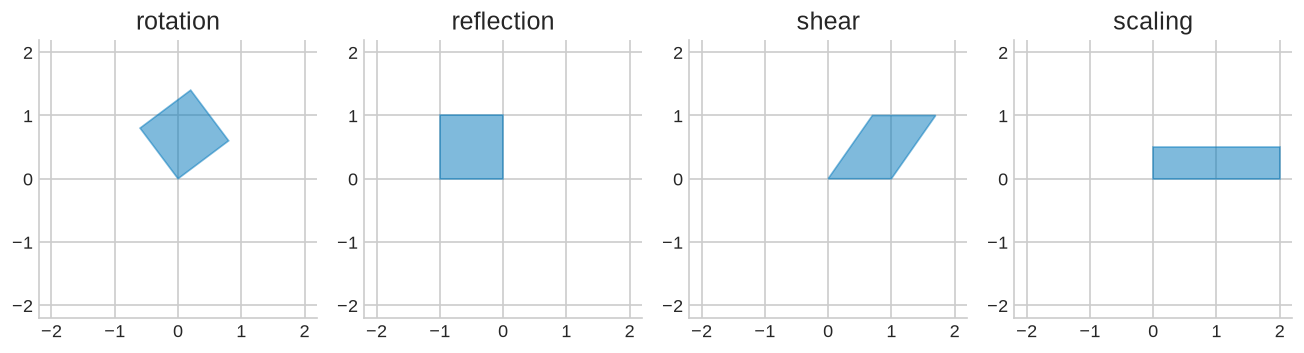

PASS: reflection flips orientation (det < 0)


In [24]:

def area(P):
    x, y = P[0], P[1]
    return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))
sq = np.array([[0, 1, 1, 0], [0, 0, 1, 1]], dtype=float)
maps = {"rotation": np.array([[0.8, -0.6], [0.6, 0.8]]), "reflection": np.array([[-1.0, 0], [0, 1]]),
        "shear": np.array([[1.0, 0.7], [0, 1]]), "scaling": np.array([[2.0, 0], [0, 0.5]])}
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, (name, M) in zip(axes, maps.items()):
    T = M @ sq
    ratio = area(T) / area(sq)
    check_close(f"{name}: |det| = area ratio", abs(np.linalg.det(M)), ratio, 1e-10)
    print(f"{name}: det = {np.linalg.det(M):+.2f}, signed area ratio {area(T)/area(sq):.2f}")
    ax.fill(T[0], T[1], color=WONG[0], alpha=0.5); ax.set_title(name); ax.set_aspect('equal'); ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
plt.tight_layout(); plt.show()
check_true("reflection flips orientation (det < 0)", np.linalg.det(maps["reflection"]) < 0)

## 14. Projections: Idempotent, Symmetric, Spectrum in {0, 1}

A projection satisfies P^2 = P; an orthogonal projection also P^T = P, and then its eigenvalues are only 0 and 1. This cell builds the projection onto a random subspace both ways and audits all three properties, connecting projections to least squares (Section 9 of 03-02).

In [25]:

rng = np.random.default_rng(42)
B = rng.normal(size=(6, 2))
P = B @ np.linalg.pinv(B)
check_close("idempotent: P^2 = P", P @ P, P, 1e-12)
check_close("symmetric: P^T = P", P.T, P, 1e-12)
ev = np.linalg.eigvalsh(P)
check_true("eigenvalues in {0,1}", np.allclose(np.sort(ev), [0, 0, 0, 0, 1, 1], atol=1e-10))
x = rng.normal(size=6)
check_close("projected part is fixed by P", P @ (P @ x), P @ x, 1e-12)
check_close("residual orthogonal to projection", (x - P @ x) @ (P @ x), 0.0, 1e-12)
print(f"rank of projection (trace) = {np.trace(P):.1f} = subspace dimension 2")

PASS: idempotent: P^2 = P (max err 2.22e-16, tol 1e-12)
PASS: symmetric: P^T = P (max err 1.11e-16, tol 1e-12)
PASS: eigenvalues in {0,1}
PASS: projected part is fixed by P (max err 8.33e-17, tol 1e-12)
PASS: residual orthogonal to projection (max err 5.65e-17, tol 1e-12)
rank of projection (trace) = 2.0 = subspace dimension 2


## 15. Orthogonal Maps Preserve the Metric

Q is orthogonal iff it preserves every norm and inner product - the definition of a rigid motion (plus possible reflection). This cell verifies metric preservation on random vectors and shows a non-orthogonal map failing it.

In [26]:

rng = np.random.default_rng(42)
Q, _ = np.linalg.qr(rng.normal(size=(5, 5)))
X = rng.normal(size=(5, 30))
check_close("norms preserved", np.linalg.norm(Q @ X, axis=0), np.linalg.norm(X, axis=0), 1e-12)
G0 = X.T @ X; G1 = (Q @ X).T @ (Q @ X)
check_close("Gram (all inner products) preserved", G1, G0, 1e-10)
A = rng.normal(size=(5, 5))
dev = np.max(np.abs((A @ X).T @ (A @ X) - G0))
print(f"max Gram deviation: orthogonal ~1e-15 scale vs general map {dev:.2f}")
check_true("general map distorts the metric", dev > 0.1)
check_close("|det Q| = 1", abs(np.linalg.det(Q)), 1.0, 1e-12)

PASS: norms preserved (max err 8.88e-16, tol 1e-12)
PASS: Gram (all inner products) preserved (max err 5.33e-15, tol 1e-10)
max Gram deviation: orthogonal ~1e-15 scale vs general map 44.99
PASS: general map distorts the metric
PASS: |det Q| = 1 (max err 6.66e-16, tol 1e-12)


## 16. The Discrete Fourier Transform Is a Linear Map - and Unitary

The DFT is a matrix: F with entries omega^{jk}/sqrt(n) is unitary, which is why the Fourier transform preserves energy (Parseval). This cell verifies unitarity and Parseval on a random signal - the linear-algebraic heart of Chapter 20.

In [27]:

n = 16
j = np.arange(n)
F = np.exp(-2j * np.pi * np.outer(j, j) / n) / np.sqrt(n)
check_close("F unitary: F^H F = I", F.conj().T @ F, np.eye(n), 1e-12)
rng = np.random.default_rng(42)
x = rng.normal(size=n) + 1j * rng.normal(size=n)
check_close("Parseval: energy preserved", np.linalg.norm(F @ x), np.linalg.norm(x), 1e-12)
check_close("inverse is conjugate transpose", np.linalg.inv(F), F.conj().T, 1e-10)
print("DFT: a unitary change of basis from time to frequency coordinates")

PASS: F unitary: F^H F = I (max err 1.82e-15, tol 1e-12)
PASS: Parseval: energy preserved (max err 8.88e-16, tol 1e-12)
PASS: inverse is conjugate transpose (max err 1.62e-15, tol 1e-10)
DFT: a unitary change of basis from time to frequency coordinates


/tmp/ipykernel_65124/1195852134.py:5: ComplexWarning: Casting complex values to real discards the imaginary part
  err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))


## 17. A Neural Layer's Jacobian Is a Linear Map (Finite-Difference Audit)

For a fixed input, the local behaviour of a smooth network layer is its Jacobian - a linear transformation. This cell estimates the Jacobian of a tanh MLP layer by finite differences and verifies that the linearisation predicts nearby outputs.

In [28]:

rng = np.random.default_rng(42)
W1 = rng.normal(scale=0.8, size=(6, 4)); b1 = rng.normal(scale=0.3, size=6)
f = lambda x: np.tanh(W1 @ x + b1)
x0 = rng.normal(size=4)
eps = 1e-6
J = np.column_stack([(f(x0 + eps * np.eye(4)[i]) - f(x0 - eps * np.eye(4)[i])) / (2 * eps) for i in range(4)])
dx = 1e-3 * rng.normal(size=4)
pred = f(x0) + J @ dx
err = np.linalg.norm(f(x0 + dx) - pred)
print(f"linearisation error at ||dx||={np.linalg.norm(dx):.1e}: {err:.2e} (expect O(||dx||^2))")
check_true("Jacobian predicts nearby outputs (err < 1e-5)", err < 1e-5)
check_close("Jacobian matches analytic diag(1-tanh^2) W", J, (1 - np.tanh(W1 @ x0 + b1)**2)[:, None] * W1, 1e-6)

linearisation error at ||dx||=1.5e-03: 9.76e-07 (expect O(||dx||^2))
PASS: Jacobian predicts nearby outputs (err < 1e-5)
PASS: Jacobian matches analytic diag(1-tanh^2) W (max err 6.00e-11, tol 1e-06)


## 18. Diagonalisation Is a Change to the Eigenbasis

Diagonalisation is not a factorisation trick; it is §11's change of basis where the new basis vectors are eigenvectors, so the map becomes pure scaling. This cell changes basis, verifies the diagonal action coordinatewise, and shows where it breaks for a defective map.

In [29]:

A = np.array([[2.0, 1.0], [0.0, 3.0]])
w, V = np.linalg.eig(A)
D = np.linalg.solve(V, A) @ V
check_close("in eigenbasis the map is diagonal", D, np.diag(np.diag(D)), 1e-10)
check_close("diagonal entries are eigenvalues", np.sort(np.diag(D).real), np.sort(w.real), 1e-10)
Ad = np.array([[1.0, 1.0], [0.0, 1.0]])
wd, Vd = np.linalg.eig(Ad)
print(f"defective example: cond(V) = {np.linalg.cond(Vd):.2e} (huge = no usable eigenbasis)")
check_true("defective map has ill-conditioned eigenvector matrix", np.linalg.cond(Vd) > 1e6)

PASS: in eigenbasis the map is diagonal (max err 0.00e+00, tol 1e-10)
PASS: diagonal entries are eigenvalues (max err 0.00e+00, tol 1e-10)
defective example: cond(V) = 9.01e+15 (huge = no usable eigenbasis)
PASS: defective map has ill-conditioned eigenvector matrix


/tmp/ipykernel_65124/1195852134.py:5: ComplexWarning: Casting complex values to real discards the imaginary part
  err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))


## 19. Polynomial Bases and the Vandermonde Warning

Representing polynomials by coefficients is a basis choice; evaluating at points is a linear map - the Vandermonde matrix. This cell fits a polynomial through points by solving the Vandermonde system and watches conditioning explode with degree, the basis-choice lesson behind orthogonal polynomial bases.

In [30]:

rng = np.random.default_rng(42)
for deg in [3, 6, 9, 12]:
    xs = np.linspace(-1, 1, deg + 1)
    V = np.vander(xs, deg + 1, increasing=True)
    print(f"degree {deg}: cond(V) = {np.linalg.cond(V):.2e}")
xs = np.linspace(-1, 1, 6)
V = np.vander(xs, 6, increasing=True)
coef_true = np.array([1.0, 0.5, -2, 0.3, 0.1, 0.05])
y = V @ coef_true
coef = np.linalg.solve(V, y)
check_close("coefficients recovered at moderate degree", coef, coef_true, 1e-6)
check_true("conditioning grows with degree", np.linalg.cond(np.vander(np.linspace(-1,1,13), 13, increasing=True)) > 1e5)

degree 3: cond(V) = 8.01e+00
degree 6: cond(V) = 1.90e+02
degree 9: cond(V) = 4.63e+03
degree 12: cond(V) = 1.23e+05
PASS: coefficients recovered at moderate degree (max err 2.22e-15, tol 1e-06)
PASS: conditioning grows with degree


## 20. Least Squares Is Projection by a Linear Map

The fitted values are H b with the hat matrix H = U U^T from the SVD: an orthogonal projection (idempotent, symmetric) onto the column space. This cell audits H as a transformation - its eigenvalues, its action, and the residual's orthogonality (consolidating Sections 9/14).

In [31]:

rng = np.random.default_rng(42)
A = rng.normal(size=(30, 5)); b = rng.normal(size=30)
U, s, Vt = np.linalg.svd(A, full_matrices=False)
H = U @ U.T
check_close("H idempotent", H @ H, H, 1e-12)
check_close("H symmetric", H.T, H, 1e-12)
fit = H @ b
check_close("residual orthogonal to fitted", (b - fit) @ fit, 0.0, 1e-10)
x, *_ = np.linalg.lstsq(A, b, rcond=None)
check_close("projection equals lstsq fit", fit, A @ x, 1e-10)
print(f"hat matrix: {H.shape}, rank {np.linalg.matrix_rank(H)} = number of features 5")

PASS: H idempotent (max err 2.15e-16, tol 1e-12)
PASS: H symmetric (max err 0.00e+00, tol 1e-12)
PASS: residual orthogonal to fitted (max err 2.40e-15, tol 1e-10)
PASS: projection equals lstsq fit (max err 2.19e-15, tol 1e-10)
hat matrix: (30, 30), rank 5 = number of features 5


---

## Summary

| Concept | Key Formula | AI Relevance |
| --- | --- | --- |
| Rank-Nullity | $\text{rank}(T) + \text{nullity}(T) = \dim(V)$ | LoRA parameter efficiency |
| Change of basis | $[T]_{\mathcal{B}'} = P^{-1}[T]_{\mathcal{B}}P$ | Diagonalization, eigenbases |
| Projection | $P^2 = P$, $P = P^\top$ | Attention heads, layer norm |
| Dual map | $(T^\top f)(\mathbf{v}) = f(T(\mathbf{v}))$ | Backpropagation via $W^\top$ |
| Jacobian chain | $J_{g\circ f} = J_g \cdot J_f$ | Automatic differentiation |
| Affine map | $f(\mathbf{x}) = A\mathbf{x} + \mathbf{b}$ | Neural layers with bias |
| Linear probe | $\hat{y} = \text{sign}(\mathbf{w}^\top\mathbf{h})$ | Linear representation hypothesis |

**Next:** [Exercises Notebook](exercises.ipynb) — 8 graded exercises

**Then:** [§05 Orthogonality and Orthonormality](../05-Orthogonality-and-Orthonormality/notes.md)